In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import re
import scanpy as sc
import pathlib
import warnings
import gc
import os
warnings.filterwarnings('ignore')

sc.set_figure_params(figsize=(4, 4))

# Read-in the data set for the cardiac niches

In [2]:
adata = sc.read_h5ad("Global_lognormalised.h5ad")

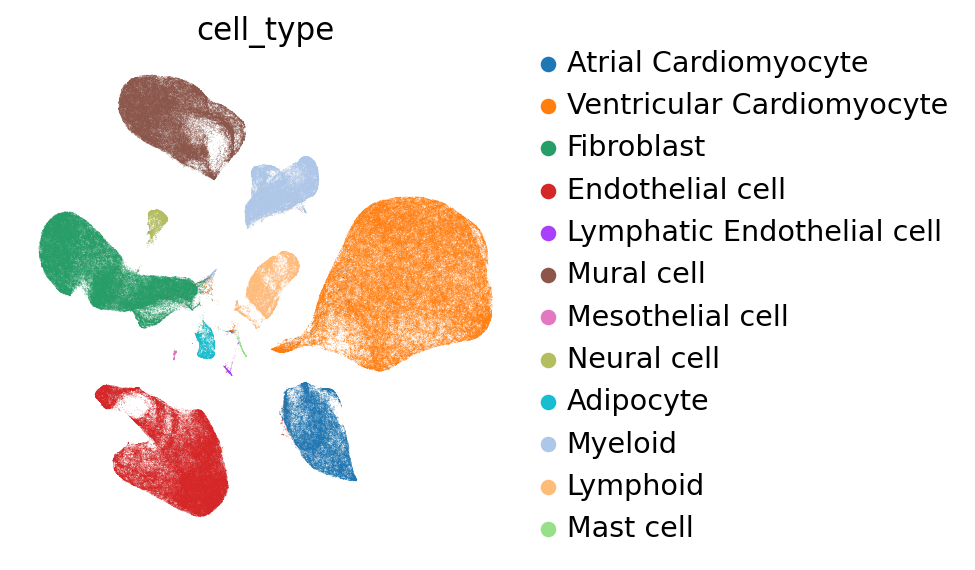

In [3]:
sc.pl.umap(
    adata,
    color=["cell_type"],
    frameon=False, ncols=1)

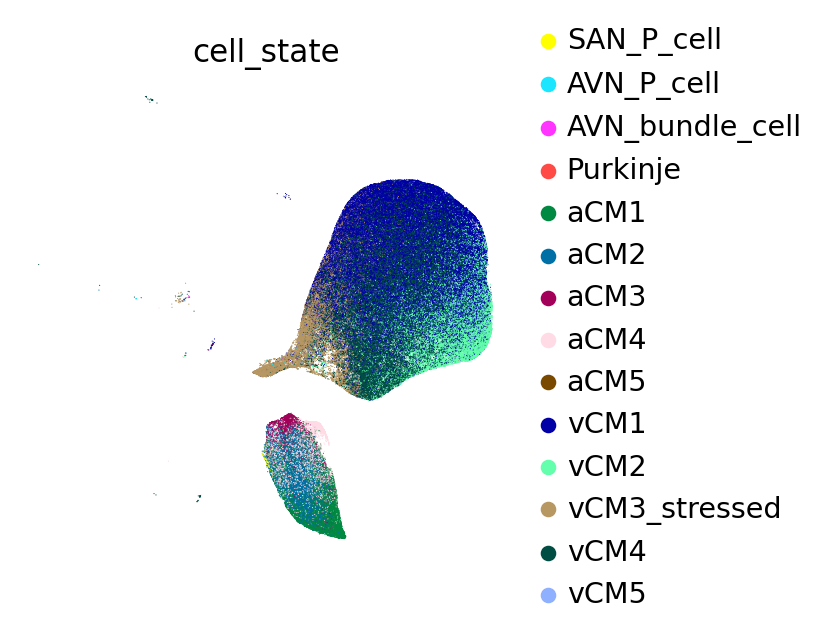

In [4]:
CM = adata[adata.obs["cell_type"].isin(['Atrial Cardiomyocyte', 'Ventricular Cardiomyocyte'])]
CM.obs["comb_anno"] = CM.obs["cell_state"].str.extract(r"^([a-zA-Z]+)")
CM = CM[~(CM.obs["cell_state"].isin(['unclassified']))]
sc.pl.umap(
    CM,
    color=["cell_state"], size=1, sort_order=False,
    frameon=False, ncols=1)

## Plot the same genes for the potassium channels in the cardiac niches

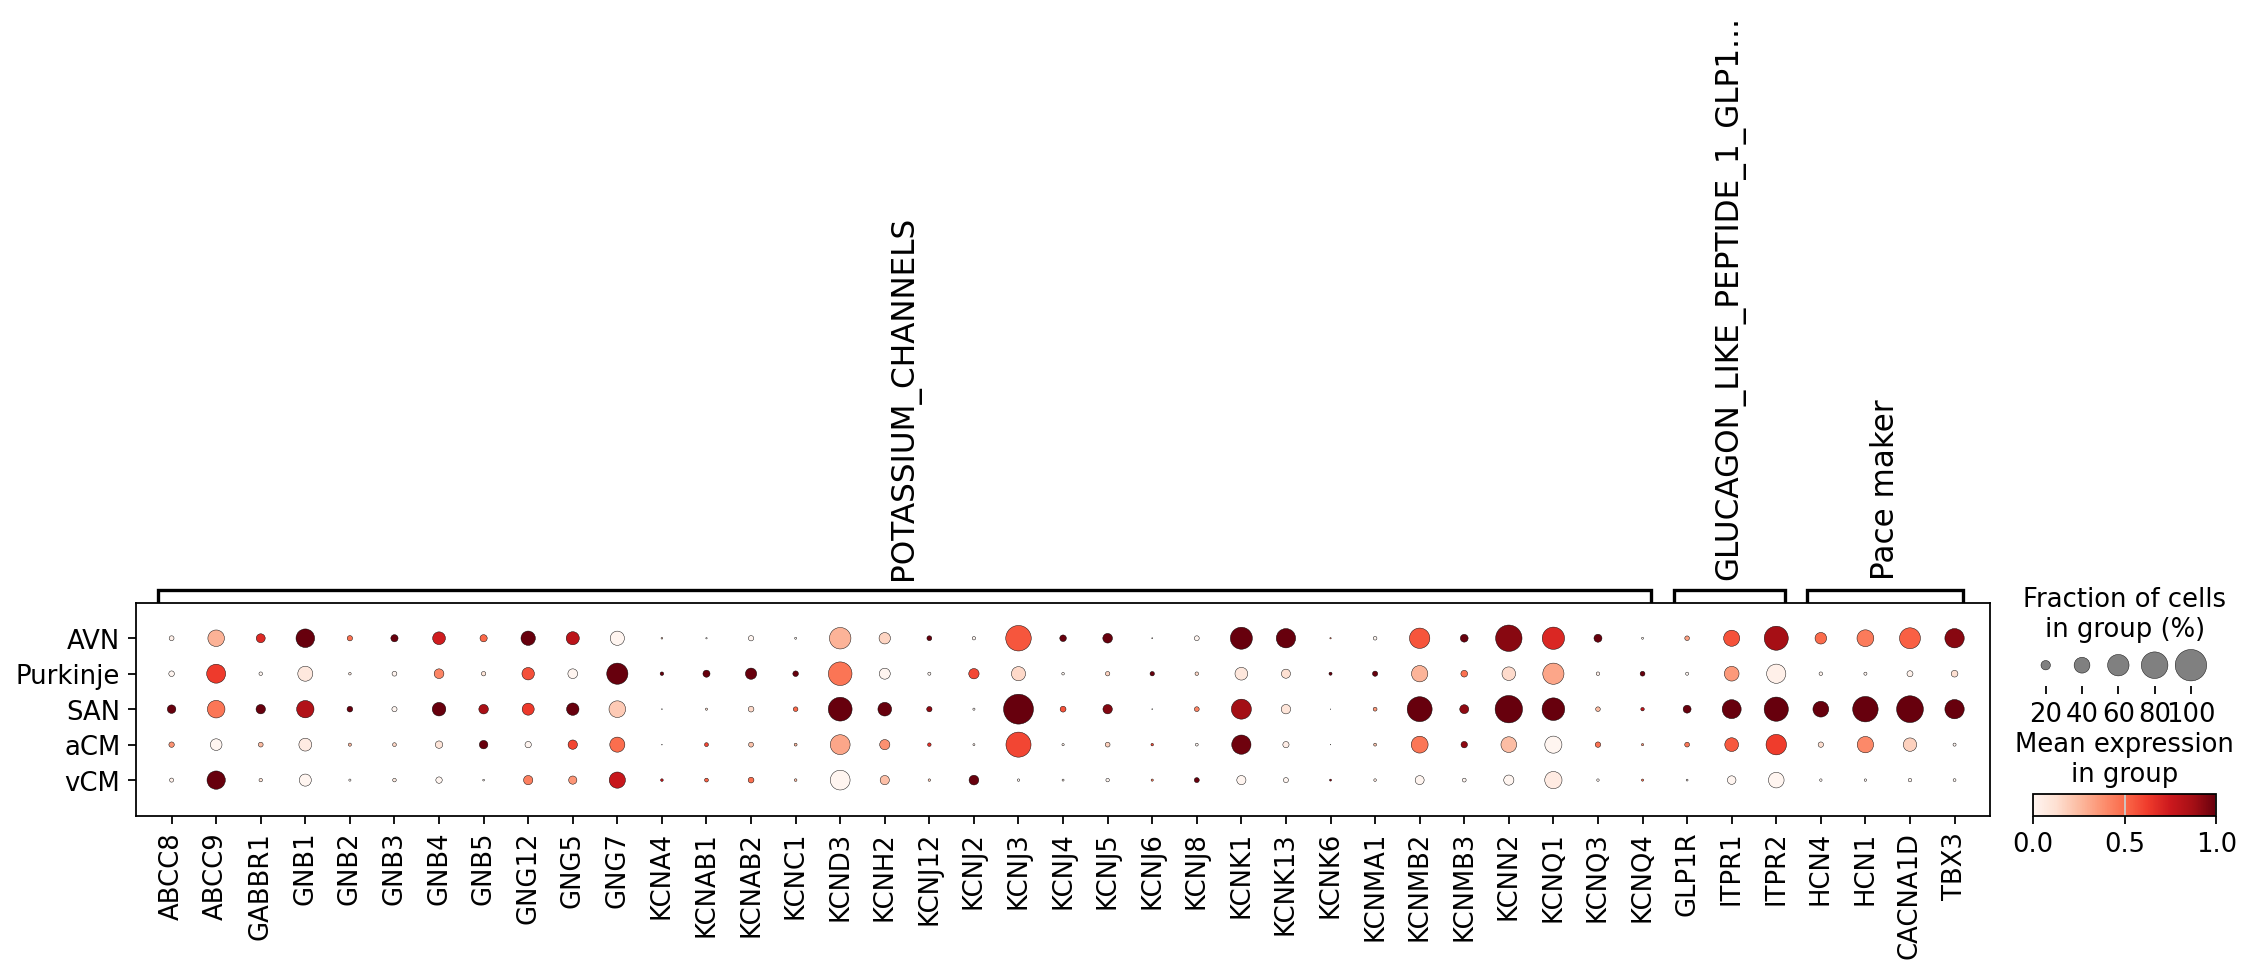

In [5]:
gene_dict = {'POTASSIUM_CHANNELS': ['ABCC8',
  'ABCC9',
  'GABBR1',
  'GNB1',
  'GNB2',
  'GNB3',
  'GNB4',
  'GNB5',
  'GNG12',
  'GNG5',
  'GNG7',
  'KCNA4',
  'KCNAB1',
  'KCNAB2',
  'KCNC1',
  'KCND3',
  'KCNH2',
  'KCNJ12',
  'KCNJ2',
  'KCNJ3',
  'KCNJ4',
  'KCNJ5',
  'KCNJ6',
  'KCNJ8',
  'KCNK1',
  'KCNK13',
  'KCNK6',
  'KCNMA1',
  'KCNMB2',
  'KCNMB3',
  'KCNN2',
  'KCNQ1',
  'KCNQ3',
  'KCNQ4'],
 'GLUCAGON_LIKE_PEPTIDE_1_GLP1...': ['GLP1R', 'ITPR1', 'ITPR2'],
 'Pace maker': ['HCN4', 'HCN1', 'CACNA1D', 'TBX3']}

sc.pl.dotplot(
    CM,
    var_names=gene_dict,
    groupby="comb_anno",
    standard_scale="var",
    show=True
)

# Additional plots for the AP

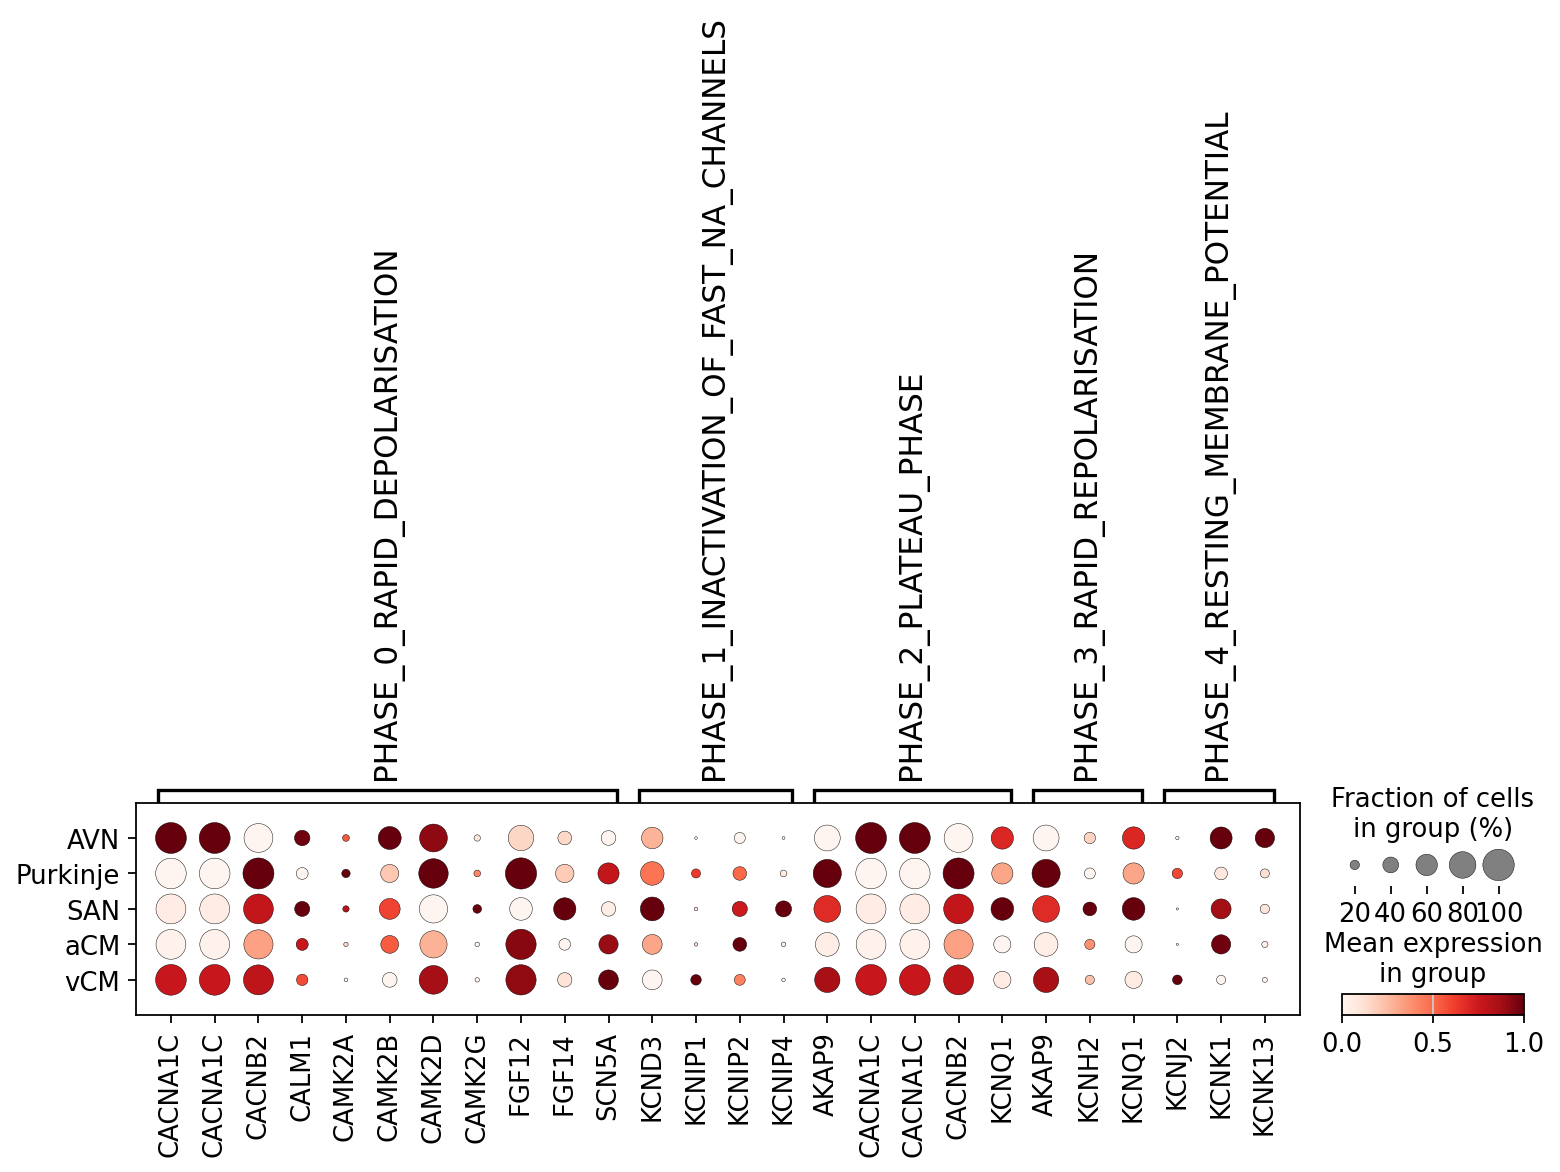

In [6]:
cardiac_ap_phase_genes = {
    "PHASE_0_RAPID_DEPOLARISATION": [
        "CACNA1C", "CACNA1C", "CACNA2D2", "CACNB1", "CACNB2", "CACNG4", "CACNG6", "CACNG7",
        "CACNG8", "CALM1", "CAMK2A", "CAMK2B", "CAMK2D", "CAMK2G", "FGF11", "FGF11", "FGF12",
        "FGF13", "FGF14", "RANGRF", "SCN10A", "SCN11A", "SCN1A", "SCN1B", "SCN2A", "SCN2B",
        "SCN3A", "SCN3B", "SCN4A", "SCN4B", "SCN5A", "SCN7A", "SCN8A", "SCN9A"
    ],
    "PHASE_1_INACTIVATION_OF_FAST_NA_CHANNELS": [
        "KCND1", "KCND2", "KCND3", "KCNIP1", "KCNIP2", "KCNIP3", "KCNIP4"
    ],
    "PHASE_2_PLATEAU_PHASE": [
        "AKAP9", "CACNA1C", "CACNA1C", "CACNA2D2", "CACNB1", "CACNB2", "CACNG4", "CACNG6",
        "CACNG7", "CACNG8", "KCNE1", "KCNE2", "KCNE3", "KCNE4", "KCNE5", "KCNQ1"
    ],
    "PHASE_3_RAPID_REPOLARISATION": [
        "AKAP9", "KCNE1", "KCNE2", "KCNE3", "KCNE4", "KCNE5", "KCNH2", "KCNQ1"
    ],
    "PHASE_4_RESTING_MEMBRANE_POTENTIAL": [
        "KCNJ12", "KCNJ14", "KCNJ2", "KCNJ4", "KCNK1", "KCNK10", "KCNK12", "KCNK13", "KCNK15",
        "KCNK16", "KCNK17", "KCNK18", "KCNK2", "KCNK3", "KCNK4", "KCNK5", "KCNK6", "KCNK7",
        "KCNK9"
    ],
}


# Filter for genes expressed in ≥5% of cells
min_cells = CM.n_obs * 0.05

filtered_gene_dict = {}
for category, genes in cardiac_ap_phase_genes.items():
    filtered_genes = [
        gene for gene in genes
        if gene in CM.var_names and (CM[:, gene].X > 0).sum() >= min_cells
    ]
    if filtered_genes:
        filtered_gene_dict[category] = filtered_genes

sc.pl.dotplot(
    CM,
    var_names=filtered_gene_dict,
    groupby="comb_anno",
    standard_scale="var",
    show=True
)

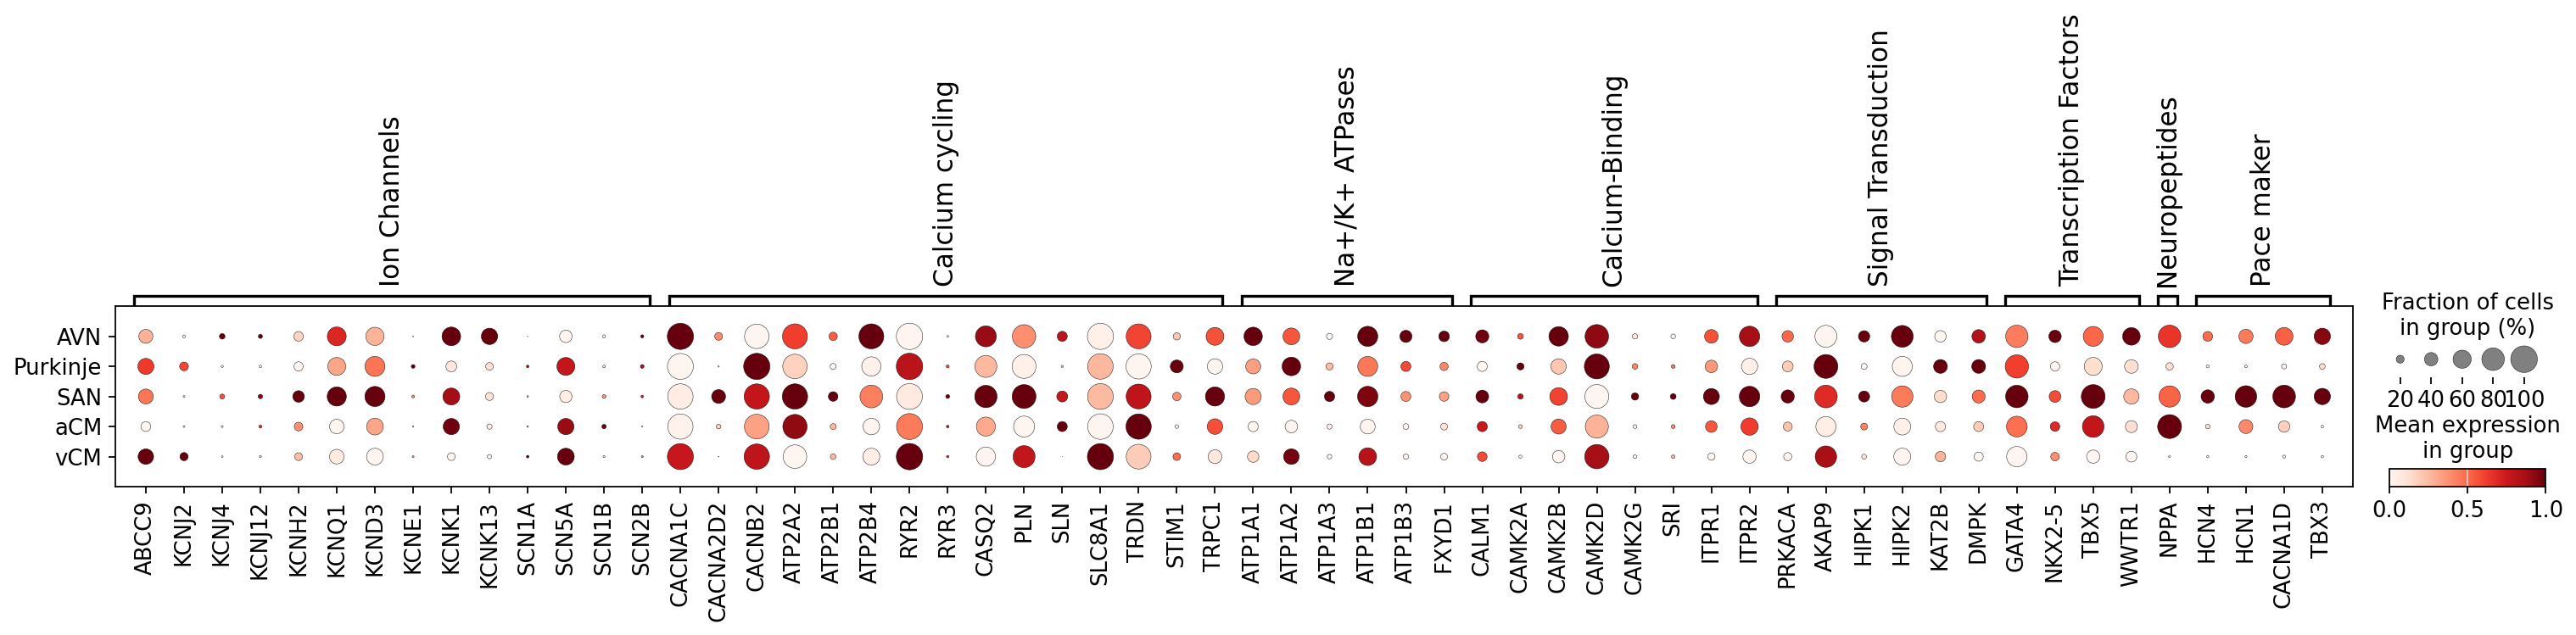

In [7]:
gene_categories = {
    "Ion Channels": [
        "ABCC9", "KCNJ2", "KCNJ4", "KCNJ11", "KCNJ12", "KCNJ14",
        "KCNH2", "KCNQ1", "KCND1", "KCND2", "KCND3",
        "KCNE1", "KCNE2", "KCNE3", "KCNE4", "KCNE5",
        "KCNK1", "KCNK2", "KCNK3", "KCNK4", "KCNK5", "KCNK6", "KCNK7",
        "KCNK9", "KCNK10", "KCNK12", "KCNK13", "KCNK15", "KCNK16", "KCNK17", "KCNK18",
        "SCN1A", "SCN2A", "SCN3A", "SCN4A", "SCN5A", "SCN7A", "SCN8A", "SCN9A",
        "SCN10A", "SCN11A", "SCN1B", "SCN2B", "SCN3B", "SCN4B"
    ],

    "Calcium cycling": [
        "CACNA1C", "CACNA2D2", "CACNB1", "CACNB2", "CACNG4", "CACNG6", "CACNG7", "CACNG8",
        "ATP2A1", "ATP2A2", "ATP2A3", "ATP2B1", "ATP2B2", "ATP2B3", "ATP2B4",
        "RYR1", "RYR2", "RYR3", "CASQ1", "CASQ2",
        "PLN", "SLN", "SLC8A1", "SLC8A2", "SLC8A3",
        "TRDN", "ORAI1", "ORAI2", "STIM1", "TRPC1"
    ],

    "Na+/K+ ATPases": [
        "ATP1A1", "ATP1A2", "ATP1A3", "ATP1A4", "ATP1B1", "ATP1B2", "ATP1B3",
        "FXYD1", "FXYD2", "FXYD3", "FXYD4", "FXYD6", "FXYD7"
    ],

    "Calcium-Binding": [
        "CALM1", "CAMK2A", "CAMK2B", "CAMK2D", "CAMK2G", "SRI", "ITPR1", "ITPR2", "ITPR3"
    ],

    "Signal Transduction": [
        "PRKACA", "AKAP9", "HIPK1", "HIPK2", "KAT2B", "DMPK"
    ],

    "Transcription Factors": [
        "GATA4", "NKX2-5", "TBX5", "WWTR1"
    ],

    "Neuropeptides": [
        "NPPA", "NPPC", "NPR1", "NPR2"
    ],

    "Pace maker":[
        "HCN4", "HCN1", "CACNA1D", "TBX3", "SHOX2"
    ]
}

# Filter for genes expressed in ≥5% of cells
min_cells = CM.n_obs * 0.025

filtered_gene_dict = {}
for category, genes in gene_categories.items():
    filtered_genes = [
        gene for gene in genes
        if gene in CM.var_names and (CM[:, gene].X > 0).sum() >= min_cells
    ]
    if filtered_genes:
        filtered_gene_dict[category] = filtered_genes

sc.pl.dotplot(
    CM,
    var_names=filtered_gene_dict,
    groupby="comb_anno",
    standard_scale="var",
    show=True
)
